In [27]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq
import matplotlib.cm as cm

import sys
sys.path.append("/Users/kevinbrennan/Desktop/Diploma/Project/Code/HATS_Code")  # folder containing HATS_functions.py

from HATS_functions import gcc_phat, corr_to_itd

angles = ["-90", "-67.5", "-45", "-22.5", "0", "22.5", "45", "67.5", "90"]
PathToFiles = "../Audio_Files/Mic_Array/Vertical/H3"

num_mics = 7
fs = 48000

recordings = {}

for angle in angles:
    folder = Path(PathToFiles) / str(angle)
    if folder.is_dir():
        recordings[angle] = {
                '0': folder / "Untitled 1-Audio.wav",
                '1': folder / "Untitled 2-Audio.wav",
                '2': folder / "Untitled 3-Audio.wav",
                '3': folder / "Untitled 4-Audio.wav",
                '4': folder / "Untitled 5-Audio.wav",
                '5': folder / "Untitled 6-Audio.wav",
                '6': folder / "Untitled 7-Audio.wav",
                '7': folder / "Untitled 8-Audio.wav"
            }
    else:
        print(f"Missing folder: {folder}")
        

In [28]:
r = 0.045
x = 2 * r * np.sin(np.radians(30))
y = 2 * r * np.sin(np.radians(60))
z = 2 * r * np.sin(np.radians(90))

dists = [[0, r, r, r, r, r, r],
         [r, 0, x, y, z, y, x],
         [r, x, 0, x, y, z, y],
         [r, y, x, 0, x, y, z],
         [r, z, y, x, 0, x, y],
         [r, y, z, y, x, 0, x],
         [r, x, y, z, y, x, 0]]


def compute_votes(source_angle_key):
    scores = {str(i): 0 for i in range(7)}
    for i in range(7):
        datax, fs = sf.read(recordings[source_angle_key][str(i)])
        for j in range(i + 1, 7):
            datay, _ = sf.read(recordings[source_angle_key][str(j)])
            correlation = gcc_phat(datax, datay)
            itd = corr_to_itd(correlation, dists[i][j], fs)
            if itd > 0:
                scores[str(i)] += 1
            else:
                scores[str(j)] += 1
    return scores


# Compute for every source angle in your recordings
results = {}
for source_angle_key in recordings.keys():
    print(f"Processing {source_angle_key}°...")
    results[source_angle_key] = compute_votes(source_angle_key)

print(results)

Processing -90°...
Processing -67.5°...
Processing -45°...
Processing -22.5°...
Processing 0°...
Processing 22.5°...
Processing 45°...
Processing 67.5°...
Processing 90°...
{'-90': {'0': 3, '1': 2, '2': 0, '3': 1, '4': 4, '5': 6, '6': 5}, '-67.5': {'0': 3, '1': 2, '2': 0, '3': 1, '4': 4, '5': 6, '6': 5}, '-45': {'0': 3, '1': 2, '2': 0, '3': 1, '4': 4, '5': 6, '6': 5}, '-22.5': {'0': 3, '1': 1, '2': 0, '3': 2, '4': 4, '5': 6, '6': 5}, '0': {'0': 3, '1': 0, '2': 1, '3': 4, '4': 6, '5': 5, '6': 2}, '22.5': {'0': 3, '1': 1, '2': 4, '3': 6, '4': 5, '5': 2, '6': 0}, '45': {'0': 3, '1': 2, '2': 5, '3': 6, '4': 4, '5': 1, '6': 0}, '67.5': {'0': 3, '1': 2, '2': 5, '3': 6, '4': 4, '5': 1, '6': 0}, '90': {'0': 3, '1': 2, '2': 5, '3': 6, '4': 4, '5': 1, '6': 0}}


In [29]:
# import matplotlib.cm as cm
# from matplotlib.transforms import Bbox

# # Source position
# source_az = -22.5
# source_height = 'H3'

# # Heights and azimuths in the test grid
# azimuths = [-90, -67.5, -45, -22.5, 0, 22.5, 45, 67.5, 90]
# heights = ['H3', 'H2', 'H1']

# # Create main grid figure
# fig, ax_grid = plt.subplots(figsize=(14, 5))
# ax_grid.set_xlim(-100, 100)
# ax_grid.set_ylim(-0.5, len(heights) - 0.5)
# ax_grid.set_xticks(azimuths)
# ax_grid.set_yticks(range(len(heights)))
# ax_grid.set_yticklabels(heights[::-1])
# ax_grid.set_xlabel('Azimuth (°)')
# ax_grid.set_ylabel('Height')
# ax_grid.grid(True, alpha=0.3)
# ax_grid.set_title('Source position on test grid')

# # Mark the actual source position
# y_pos = heights[::-1].index(source_height)
# ax_grid.plot(source_az, y_pos, 'o', color='coral', markersize=20, 
#              markeredgecolor='darkred', markeredgewidth=2, label='Source', zorder=5)
# ax_grid.plot([0, source_az], [1, y_pos], color='steelblue', linestyle='--', 
#              linewidth=2, zorder=4)

# ax_grid.legend(loc='upper right')

# plt.tight_layout()

# # Inset polar plot in corner showing the array prediction
# trans = ax_grid.transData.transform((0, 1))  # azimuth 0, y_pos for H2
# fig_coords = fig.transFigure.inverted().transform(trans)

# inset_size = 0.35
# ax_inset = fig.add_axes([fig_coords[0] - inset_size/2, 
#                           fig_coords[1] - inset_size/2,
#                           inset_size, inset_size], projection='polar')
# ax_inset.set_theta_zero_location('N')
# ax_inset.set_theta_direction(1)

# mic_angles_deg = [0, 60, 120, 180, 240, 300]
# mic_angles_rad = np.radians(mic_angles_deg)
# mic_r = 0.045

# max_score = max(scores.values())

# for i, a in enumerate(mic_angles_rad):
#     score = scores[str(i+1)]
#     intensity = score / max_score if max_score > 0 else 0
#     ax_inset.scatter(a, mic_r, s=80 + 200 * intensity, 
#                      color=cm.Blues(0.3 + 0.7 * intensity),
#                      edgecolors='steelblue', linewidths=1, zorder=5)

# score_c = scores['0']
# intensity_c = score_c / max_score if max_score > 0 else 0
# ax_inset.scatter(0, 0, s=80 + 200 * intensity_c,
#                  color=cm.Blues(0.3 + 0.7 * intensity_c),
#                  edgecolors='steelblue', linewidths=1, zorder=5)

# winning_mic = int(max(scores, key=scores.get))
# sorted_mics = sorted(scores.items(), key=lambda x: -x[1])
# second_mic = int(sorted_mics[1][0])
# winning_angle = mic_angles_deg[winning_mic - 1] if winning_mic > 0 else 0
# second_angle = mic_angles_deg[second_mic - 1] if second_mic > 0 else 0
# sector_start = np.radians(min(winning_angle, second_angle))
# sector_end = np.radians(max(winning_angle, second_angle))
# theta = np.linspace(sector_start, sector_end, 100)
# ax_inset.fill_between(theta, 0, mic_r, alpha=0.3, color='steelblue')

# circle_theta = np.linspace(0, 2*np.pi, 100)
# ax_inset.plot(circle_theta, [mic_r]*100, color='gray', linestyle='--', linewidth=0.8)

# ax_inset.set_ylim(0, 0.06)
# ax_inset.set_rticks([])
# ax_inset.set_thetagrids([])
# ax_inset.set_title('Array prediction', fontsize=10)

# plt.show()

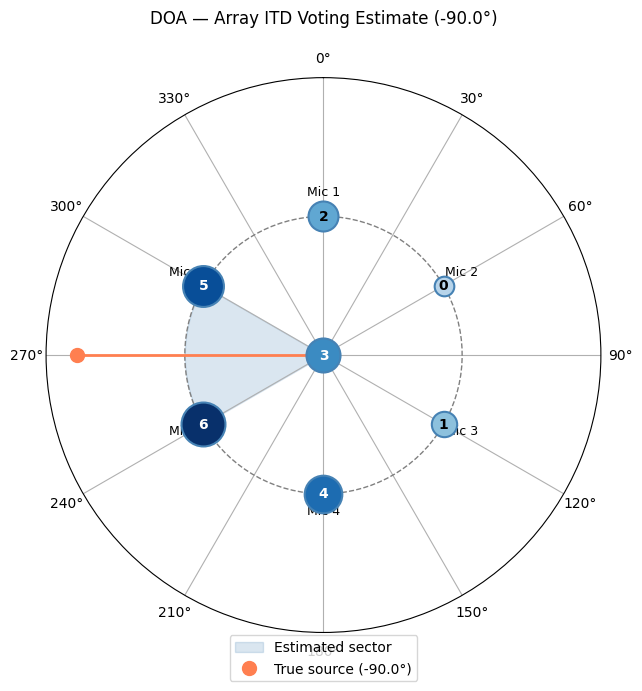

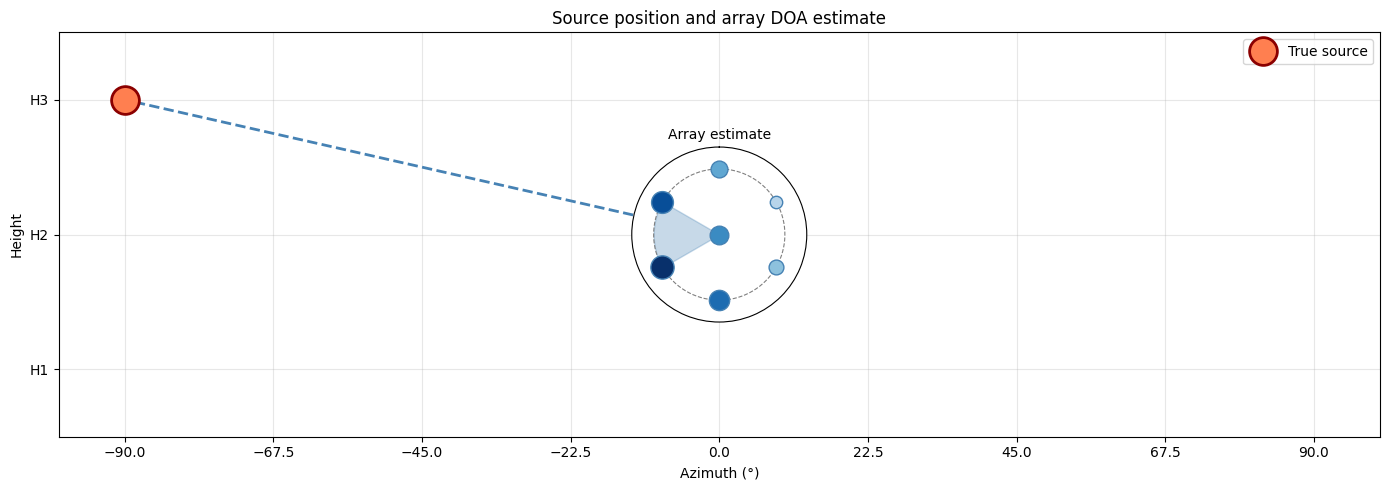

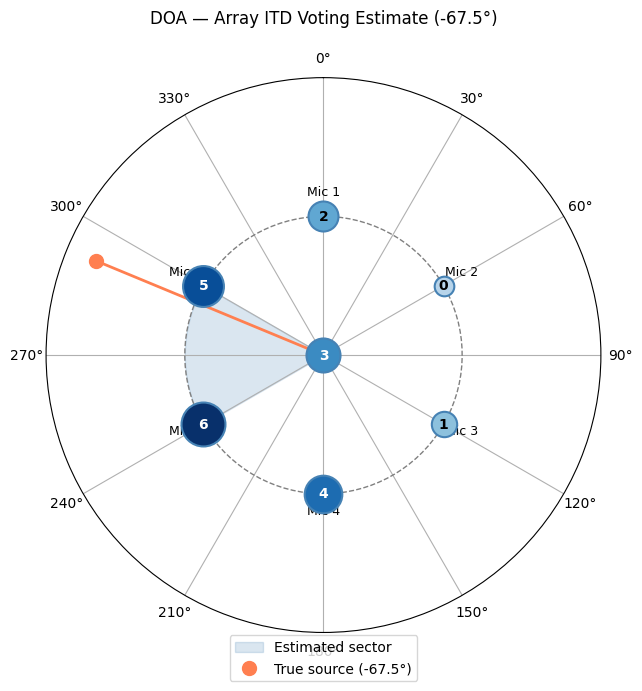

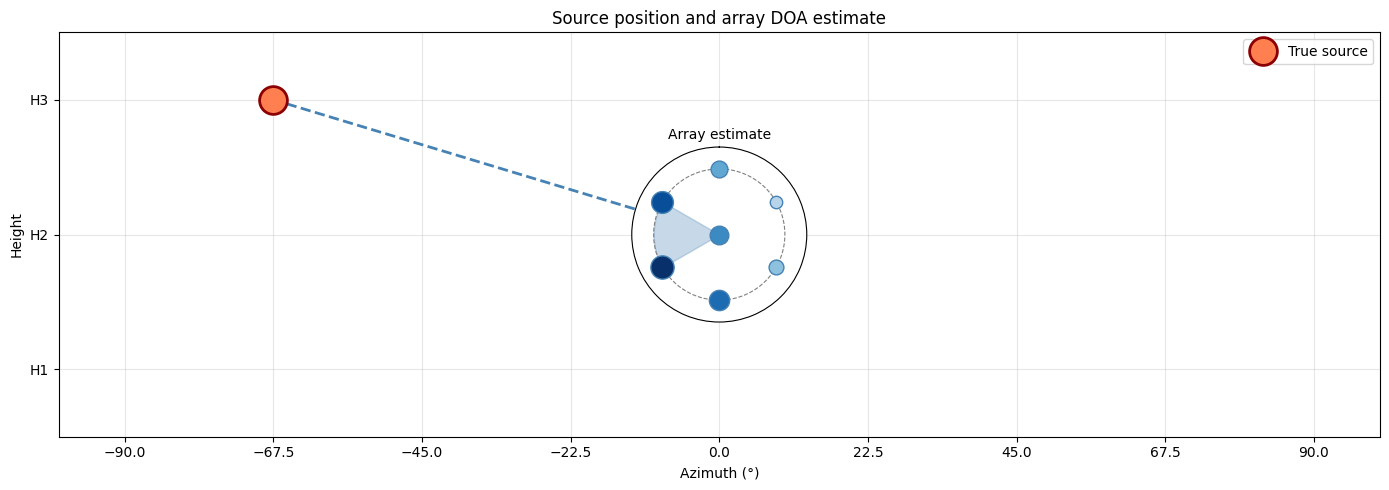

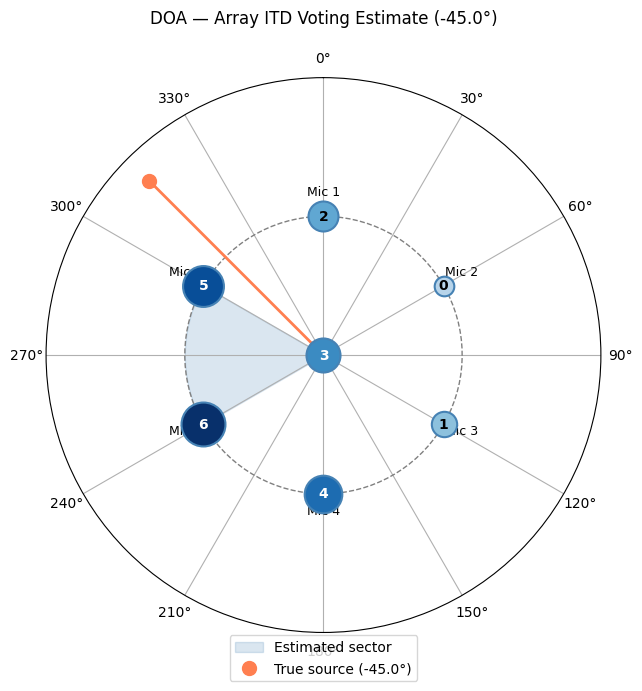

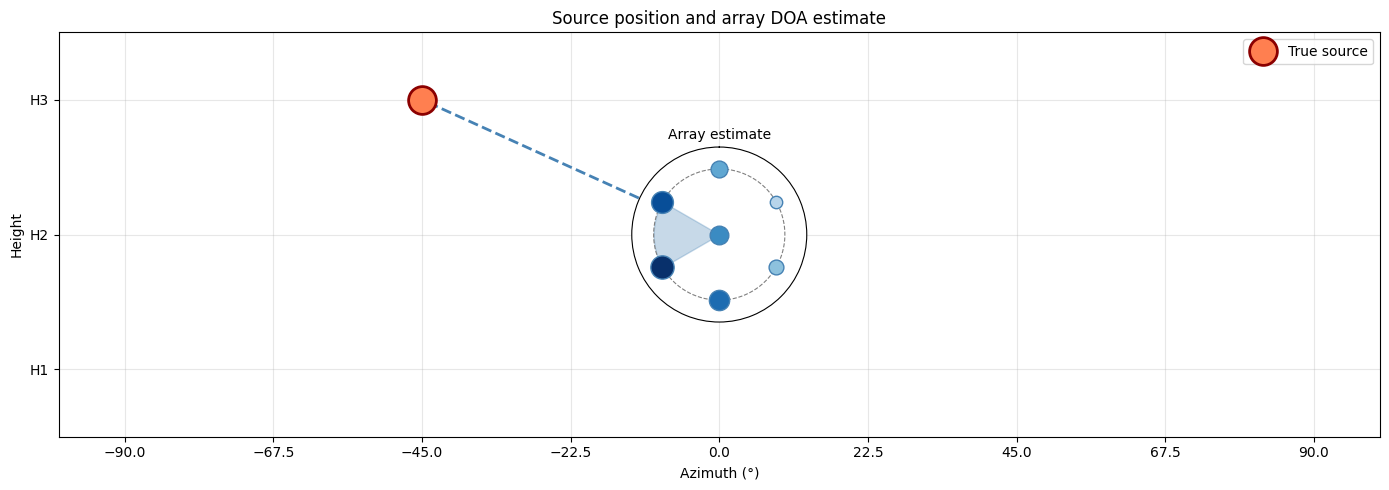

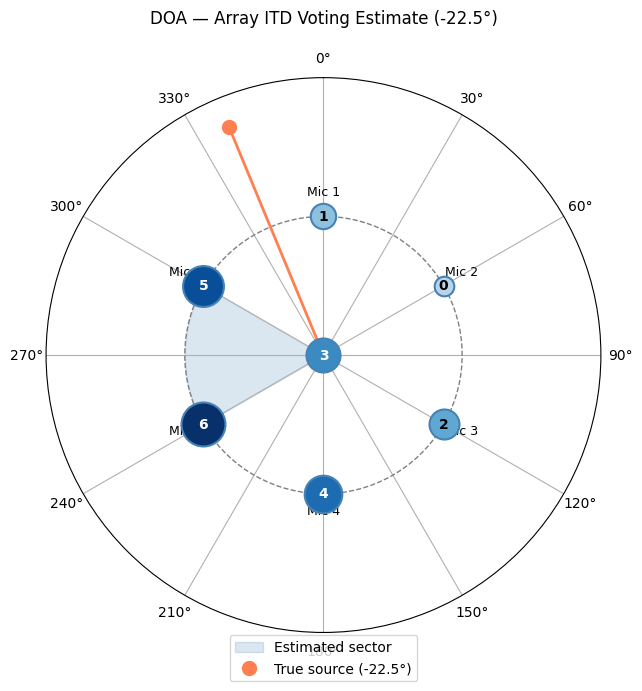

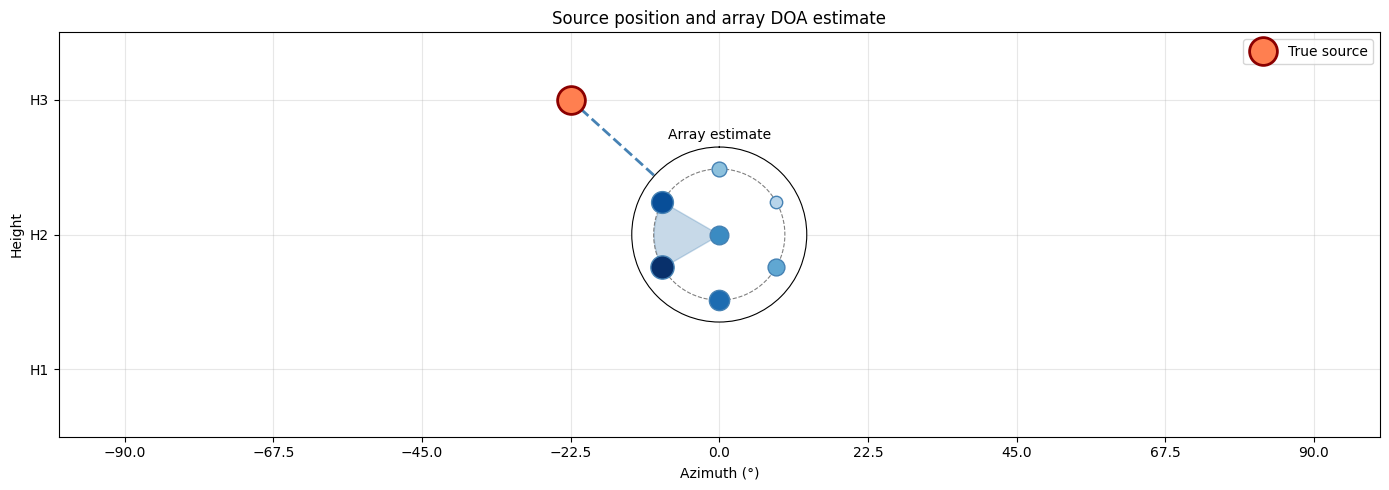

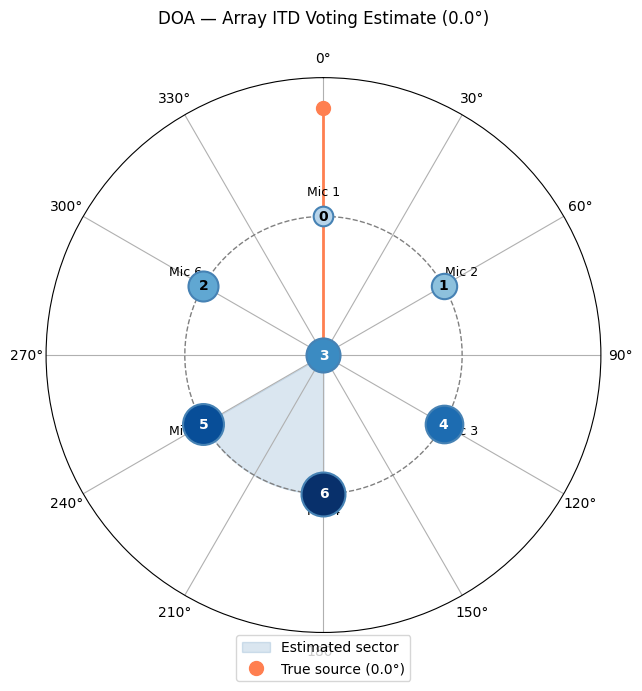

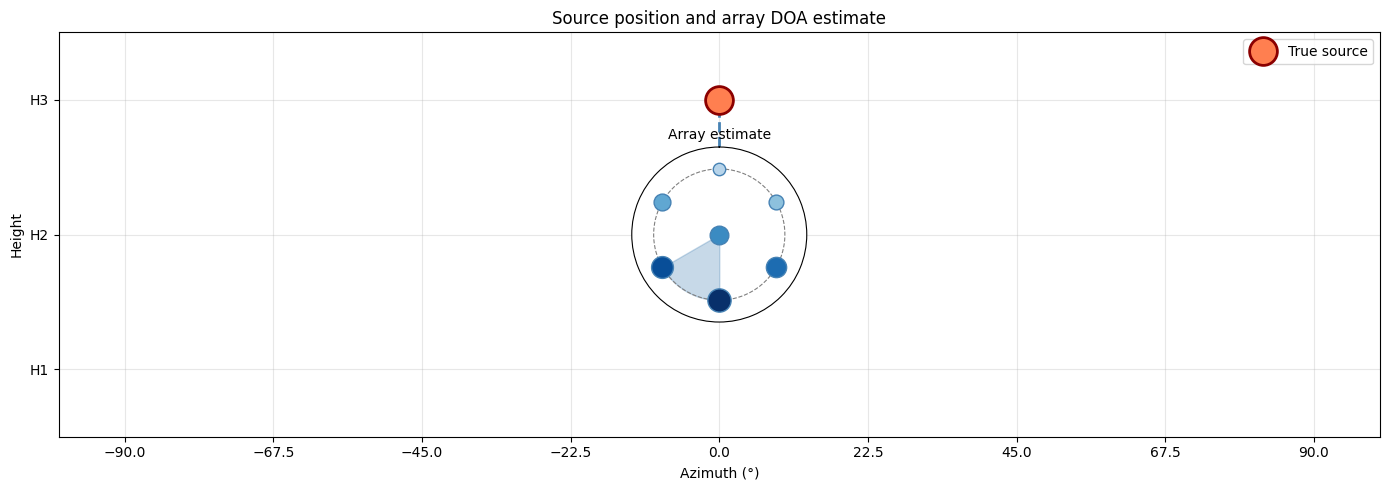

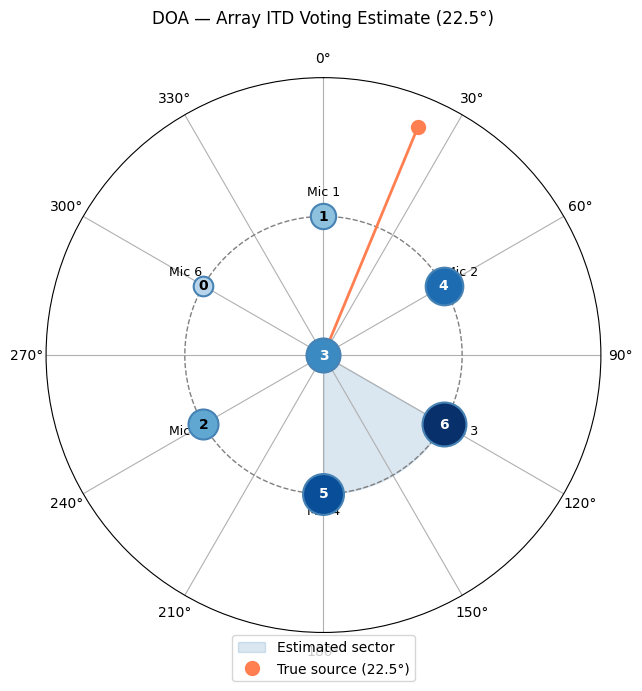

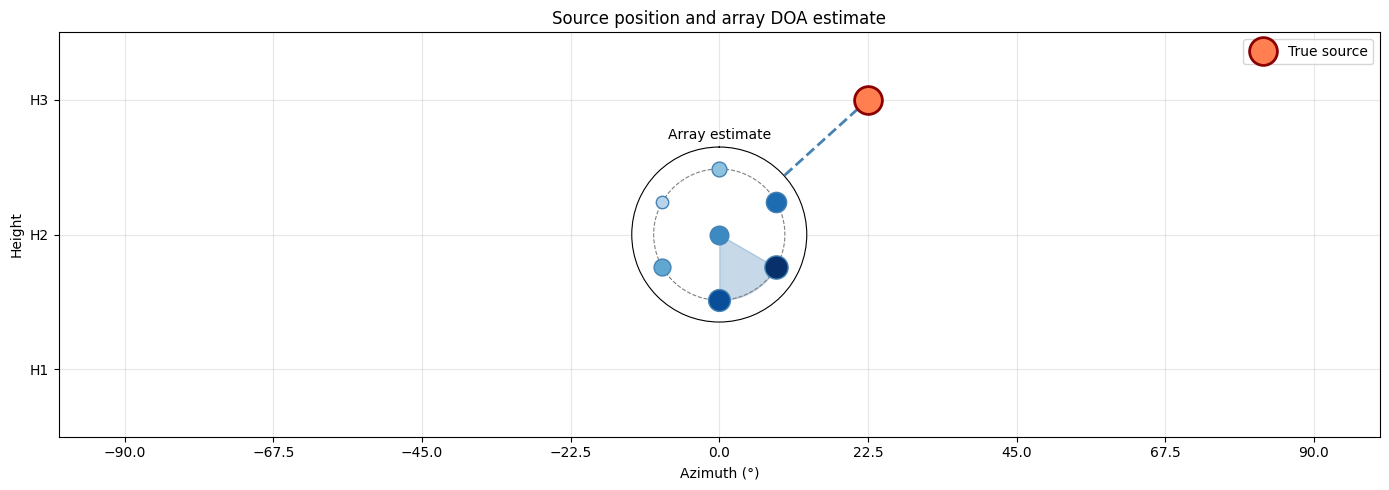

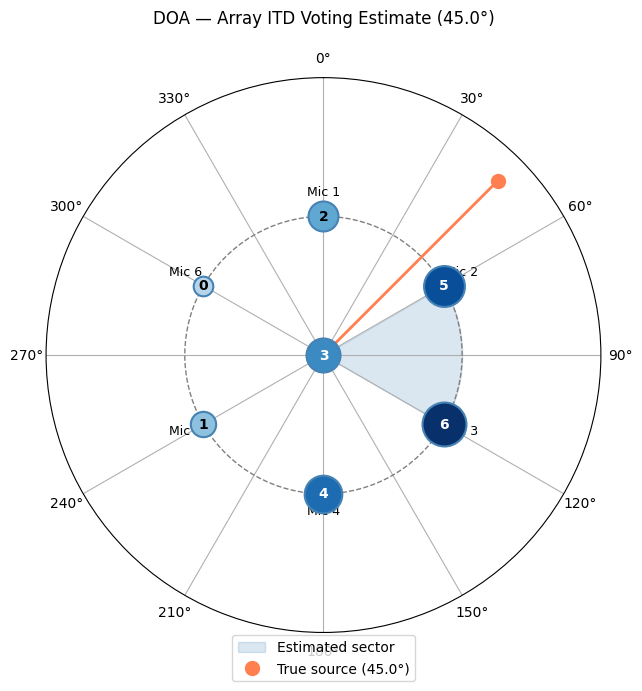

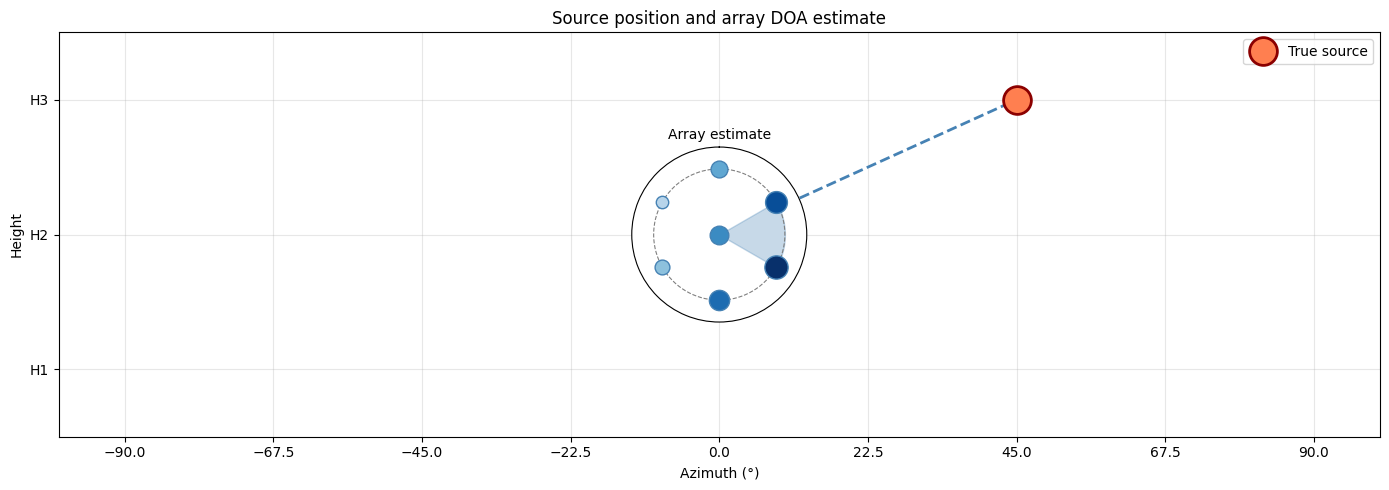

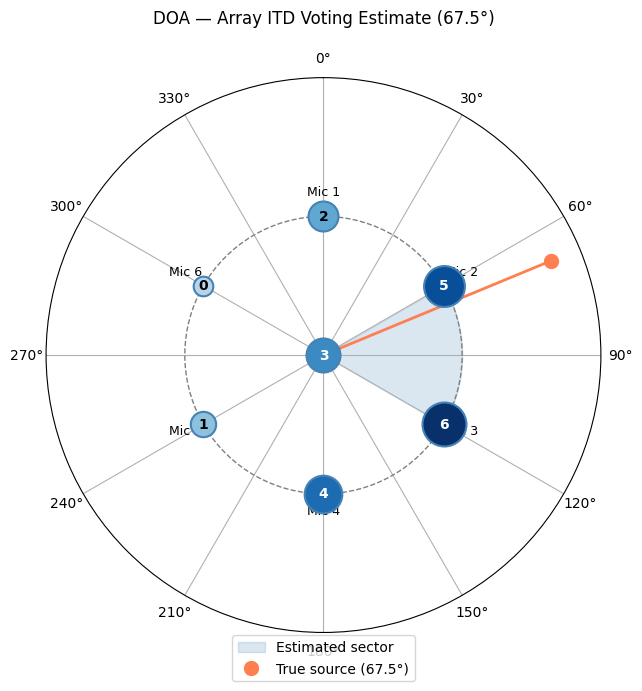

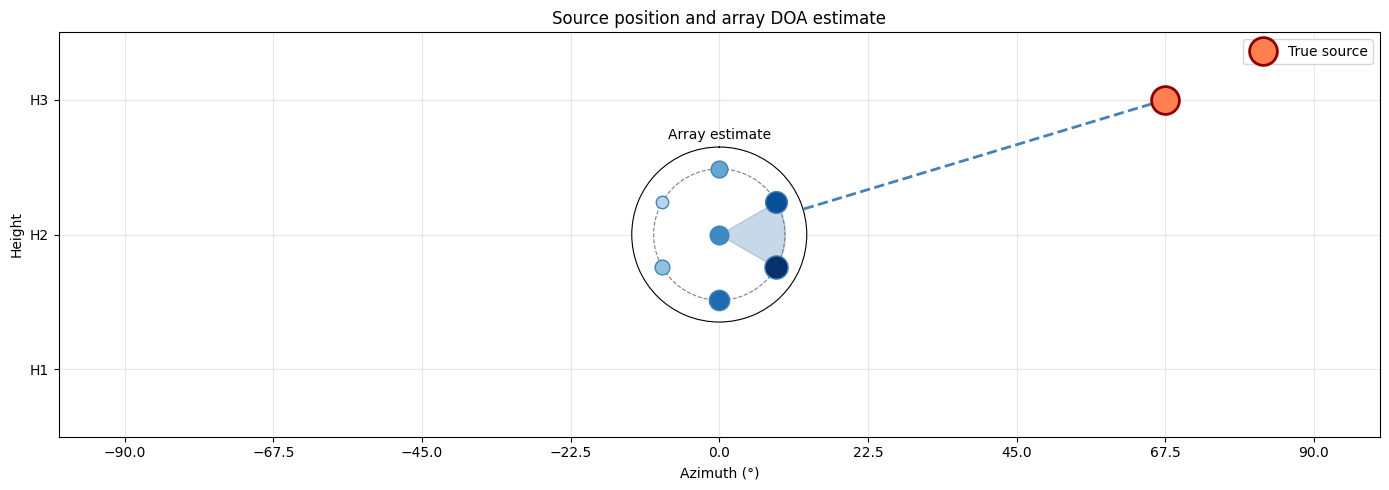

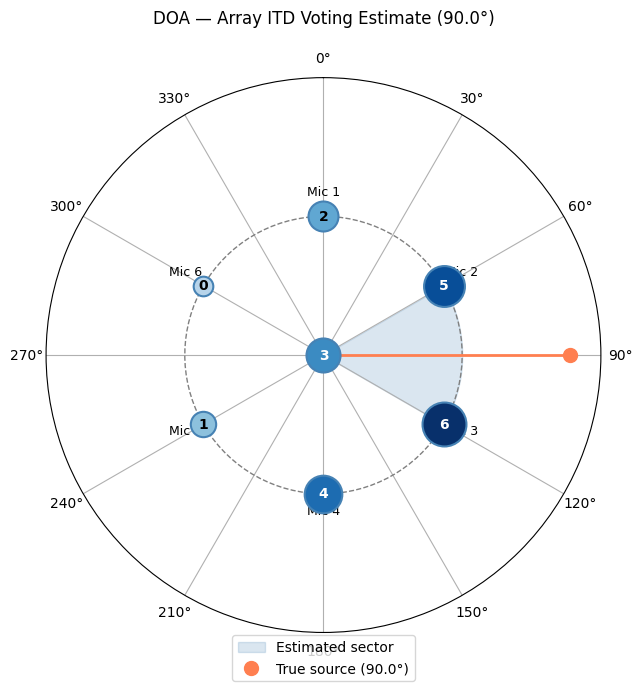

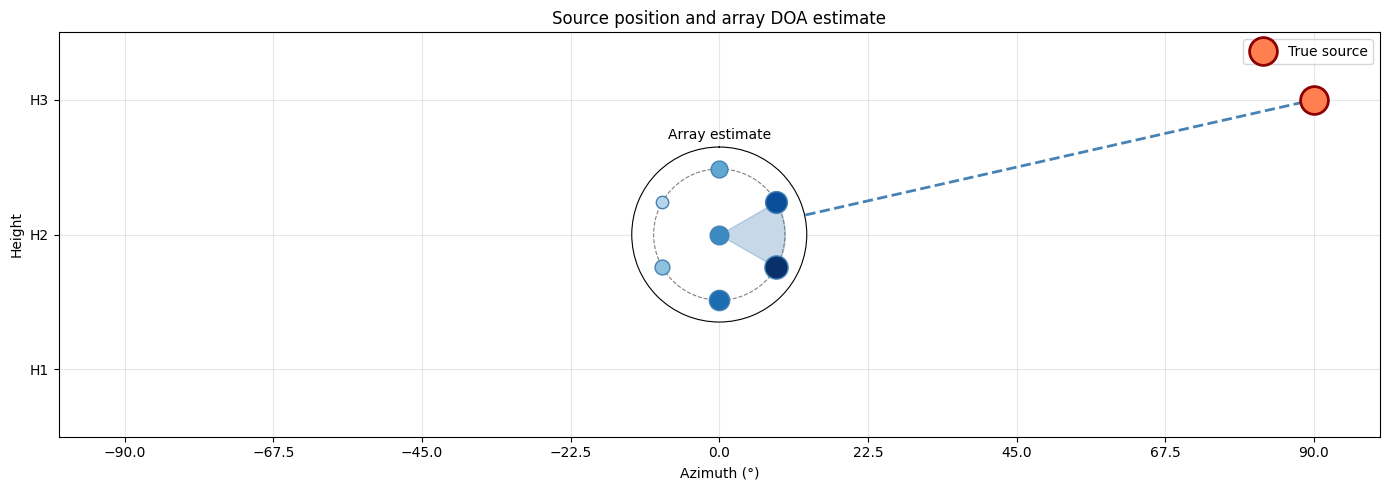

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


def save_fig(fig, name):
    fig.savefig(figures_dir / f"{name}.png", dpi=200, bbox_inches='tight')
    fig.savefig(figures_dir / f"{name}.pdf", bbox_inches='tight')


def _compute_sector(scores, mic_angles_deg):
    outer = {k: v for k, v in scores.items() if k != '0'}
    sorted_mics = sorted(outer.items(), key=lambda x: -x[1])
    a1 = mic_angles_deg[int(sorted_mics[0][0]) - 1]
    a2 = mic_angles_deg[int(sorted_mics[1][0]) - 1]
    delta = ((a2 - a1 + 180) % 360) - 180
    if delta >= 0:
        return np.radians(a1), np.radians(a1 + delta)
    return np.radians(a1 + delta), np.radians(a1)


# =============================================================================
# 1. Array ITD voting — standalone polar
# =============================================================================

def plot_array_voting(scores, true_source_deg, name):
    mic_angles_deg = [0, 60, 120, 180, 240, 300]
    mic_angles_rad = np.radians(mic_angles_deg)
    mic_r = 0.045

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)

    max_score = max(scores.values())

    for i, a in enumerate(mic_angles_rad):
        score = scores[str(i + 1)]
        intensity = score / max_score if max_score > 0 else 0
        ax.scatter(a, mic_r, s=200 + 800 * intensity,
                   color=cm.Blues(0.3 + 0.7 * intensity), zorder=5,
                   edgecolors='steelblue', linewidths=1.5)
        ax.annotate(str(score), (a, mic_r), ha='center', va='center',
                    fontsize=10, fontweight='bold',
                    color='white' if intensity > 0.4 else 'black', zorder=6)
        ax.annotate(f'Mic {i + 1}', (a, mic_r * 1.15), ha='center', fontsize=9)

    score_c = scores['0']
    intensity_c = score_c / max_score if max_score > 0 else 0
    ax.scatter(0, 0, s=200 + 800 * intensity_c,
               color=cm.Blues(0.3 + 0.7 * intensity_c), zorder=5,
               edgecolors='steelblue', linewidths=1.5)
    ax.annotate(str(score_c), (0, 0), ha='center', va='center',
                fontsize=10, fontweight='bold',
                color='white' if intensity_c > 0.4 else 'black', zorder=6)

    sector_start, sector_end = _compute_sector(scores, mic_angles_deg)
    theta = np.linspace(sector_start, sector_end, 100)
    ax.fill_between(theta, 0, mic_r, alpha=0.2, color='steelblue',
                    label='Estimated sector')

    circle_theta = np.linspace(0, 2 * np.pi, 100)
    ax.plot(circle_theta, [mic_r] * 100, color='gray',
            linestyle='--', linewidth=1)

    source_angle_rad = np.radians(true_source_deg)
    ax.plot([source_angle_rad, source_angle_rad], [0, 0.08], color='coral', lw=2)
    ax.plot(source_angle_rad, 0.08, 'o', color='coral', markersize=10,
            label=f'True source ({true_source_deg}°)')

    ax.set_ylim(0, 0.09)
    ax.set_rticks([])
    ax.set_thetagrids(np.arange(0, 360, 30),
                      labels=[f'{a}°' for a in np.arange(0, 360, 30)])
    ax.set_title(f'DOA — Array ITD Voting Estimate ({true_source_deg}°)', pad=20)
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.1))
    plt.tight_layout()

    save_fig(fig, name)
    plt.show()
    plt.close(fig)


# =============================================================================
# 2. Source position on test grid + inset array estimate
# =============================================================================

def plot_source_and_estimate(source_az, source_height, scores, name):
    azimuths = [-90, -67.5, -45, -22.5, 0, 22.5, 45, 67.5, 90]
    heights = ['H3', 'H2', 'H1']

    fig, ax_grid = plt.subplots(figsize=(14, 5))
    ax_grid.set_xlim(-100, 100)
    ax_grid.set_ylim(-0.5, len(heights) - 0.5)
    ax_grid.set_xticks(azimuths)
    ax_grid.set_yticks(range(len(heights)))
    ax_grid.set_yticklabels(heights[::-1])
    ax_grid.set_xlabel('Azimuth (°)')
    ax_grid.set_ylabel('Height')
    ax_grid.grid(True, alpha=0.3)
    ax_grid.set_title('Source position and array DOA estimate')

    y_pos = heights[::-1].index(source_height)
    ax_grid.plot(source_az, y_pos, 'o', color='coral', markersize=20,
                 markeredgecolor='darkred', markeredgewidth=2,
                 label='True source', zorder=5)
    ax_grid.plot([0, source_az], [1, y_pos], color='steelblue', linestyle='--',
                 linewidth=2, zorder=4)
    ax_grid.legend(loc='upper right')
    plt.tight_layout()

    trans = ax_grid.transData.transform((0, 1))
    fig_coords = fig.transFigure.inverted().transform(trans)
    inset_size = 0.35
    ax_inset = fig.add_axes([fig_coords[0] - inset_size/2,
                              fig_coords[1] - inset_size/2,
                              inset_size, inset_size], projection='polar')
    ax_inset.set_theta_zero_location('N')
    ax_inset.set_theta_direction(-1)

    mic_angles_deg = [0, 60, 120, 180, 240, 300]
    mic_angles_rad = np.radians(mic_angles_deg)
    mic_r = 0.045
    max_score = max(scores.values())

    for i, a in enumerate(mic_angles_rad):
        score = scores[str(i + 1)]
        intensity = score / max_score if max_score > 0 else 0
        ax_inset.scatter(a, mic_r, s=80 + 200 * intensity,
                         color=cm.Blues(0.3 + 0.7 * intensity),
                         edgecolors='steelblue', linewidths=1, zorder=5)

    score_c = scores['0']
    intensity_c = score_c / max_score if max_score > 0 else 0
    ax_inset.scatter(0, 0, s=80 + 200 * intensity_c,
                     color=cm.Blues(0.3 + 0.7 * intensity_c),
                     edgecolors='steelblue', linewidths=1, zorder=5)

    sector_start, sector_end = _compute_sector(scores, mic_angles_deg)
    theta = np.linspace(sector_start, sector_end, 100)
    ax_inset.fill_between(theta, 0, mic_r, alpha=0.3, color='steelblue')

    circle_theta = np.linspace(0, 2 * np.pi, 100)
    ax_inset.plot(circle_theta, [mic_r]*100, color='gray',
                  linestyle='--', linewidth=0.8)

    ax_inset.set_ylim(0, 0.06)
    ax_inset.set_rticks([])
    ax_inset.set_thetagrids([])
    ax_inset.set_title('Array estimate', fontsize=10)

    save_fig(fig, name)
    plt.show()
    plt.close(fig)


# =============================================================================
# BATCH SAVE using results
# =============================================================================

source_height = 'H3'  # adjust if needed

for angle_key, scores in results.items():
    plot_array_voting(scores, float(angle_key),
                      f"array_voting_{source_height}-{angle_key}")
    plot_source_and_estimate(float(angle_key), source_height, scores,
                             f"source_and_estimate_{source_height}_{angle_key}")


# CSV of the raw vote counts
import csv

with open(figures_dir / "array_voting_results.csv", 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['source_angle', 'mic_0', 'mic_1', 'mic_2',
                     'mic_3', 'mic_4', 'mic_5', 'mic_6'])
    for angle_key, scores in results.items():
        writer.writerow([angle_key] + [scores[str(i)] for i in range(7)])

In [31]:
for angle_key, scores in results.items():
    print(f"{angle_key:>7}°: {scores}")

    -90°: {'0': 3, '1': 2, '2': 0, '3': 1, '4': 4, '5': 6, '6': 5}
  -67.5°: {'0': 3, '1': 2, '2': 0, '3': 1, '4': 4, '5': 6, '6': 5}
    -45°: {'0': 3, '1': 2, '2': 0, '3': 1, '4': 4, '5': 6, '6': 5}
  -22.5°: {'0': 3, '1': 1, '2': 0, '3': 2, '4': 4, '5': 6, '6': 5}
      0°: {'0': 3, '1': 0, '2': 1, '3': 4, '4': 6, '5': 5, '6': 2}
   22.5°: {'0': 3, '1': 1, '2': 4, '3': 6, '4': 5, '5': 2, '6': 0}
     45°: {'0': 3, '1': 2, '2': 5, '3': 6, '4': 4, '5': 1, '6': 0}
   67.5°: {'0': 3, '1': 2, '2': 5, '3': 6, '4': 4, '5': 1, '6': 0}
     90°: {'0': 3, '1': 2, '2': 5, '3': 6, '4': 4, '5': 1, '6': 0}
